# Project Overheat: Predictive Maintenance AI
**AeroLogistics | Data Science Capstone Project**

**Objective:** Predict whether a machine will experience a catastrophic failure **24 hours from the current timestamp**, using IoT sensor telemetry.

**Author:** Shashikumar Raj Urs  
**Model:** Random Forest Classifier  
**Main libraries:** Python, Pandas, NumPy, Matplotlib, Scikit-learn

## 1. Business problem
Unexpected motor failures stop automated sorting operations and cause expensive downtime. This project changes maintenance from reactive repair to proactive intervention by learning patterns in temperature, vibration and voltage readings.

## 2. Project workflow
1. Load and validate the hourly IoT telemetry.
2. Sort records by timestamp and create 12-hour rolling features.
3. Shift the failure label by 24 rows to create the 24-hour-ahead target.
4. Split chronologically: first 80% for model development and final 20% for the untouched test.
5. Train a class-weighted Random Forest and evaluate rare-event detection.
6. Explain model behaviour with feature importance and maintenance recommendations.

> **Important:** This notebook embeds a compressed copy of the supplied CSV as a fallback. It can therefore run as a single notebook file. If the original CSV is placed in the same folder, the notebook will use that file instead.

## 3. Environment setup
Run this notebook from top to bottom. If any library is missing, install it in your Python environment with:
`pip install pandas numpy matplotlib scikit-learn`

In [1]:
import os
import io
import gzip
import base64
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, average_precision_score,
    balanced_accuracy_score
)

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## 4. Load the supplied IoT dataset
The source file contains 10,000 hourly observations and five columns:
- `Timestamp`
- `Sensor_Temp_C`
- `Sensor_Vibration_mm`
- `Sensor_Voltage_V`
- `Catastrophic_Failure` (0 = no failure, 1 = failure)

In [2]:
CSV_FILE = "iot_sensor_telemetry.csv"

if os.path.exists(CSV_FILE):
    df = pd.read_csv(CSV_FILE)
    data_source = f"External file: {CSV_FILE}"
else:
    # Self-contained fallback: compressed copy of the CSV supplied with this assignment.
    embedded_csv_gzip_b64 = (
        "..."
    )
    csv_bytes = gzip.decompress(base64.b64decode(embedded_csv_gzip_b64))
    df = pd.read_csv(io.BytesIO(csv_bytes))
    data_source = "Embedded copy of the supplied CSV"

print("Data source:", data_source)
print("Dataset shape:", df.shape)
display(df.head())

Data source: Embedded copy of the supplied CSV
Dataset shape: (10000, 5)


,Timestamp,Sensor_Temp_C,Sensor_Vibration_mm,Sensor_Voltage_V,Catastrophic_Failure
0,2023-01-01 00:00:00,66.490142,1.064301,220.696572,0.0
1,2023-01-01 01:00:00,64.585207,1.138900,220.566647,0.0
2,2023-01-01 02:00:00,66.943066,1.080524,218.126960,0.0
3,2023-01-01 03:00:00,69.569090,1.222084,221.159168,0.0
4,2023-01-01 04:00:00,64.297540,1.439436,217.019835,0.0


In [3]:
required_columns = [
    "Timestamp", "Sensor_Temp_C", "Sensor_Vibration_mm",
    "Sensor_Voltage_V", "Catastrophic_Failure"
]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
for col in required_columns[1:]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=required_columns).copy()
df = df.sort_values("Timestamp").reset_index(drop=True)

# Confirm that the data is hourly because the assignment defines 24 rows as 24 hours.
time_differences = df["Timestamp"].diff().dropna()
print("Rows after basic cleaning:", len(df))
print("Duplicate timestamps:", df["Timestamp"].duplicated().sum())
print("Most common timestamp interval:", time_differences.mode().iloc[0])
print("Failure label counts:")
display(df["Catastrophic_Failure"].value_counts().rename(index={0: "No failure", 1: "Failure"}))

Rows after basic cleaning: 10000
Duplicate timestamps: 0
Most common timestamp interval: 0 days 01:00:00
Failure label counts:


Catastrophic_Failure
No failure    9985
Failure         15
Name: count, dtype: int64

## 5. Exploratory data analysis
First inspect the sensor distributions and the frequency of failure events. Failure labels are rare, so accuracy alone will not be a reliable measure of model quality.

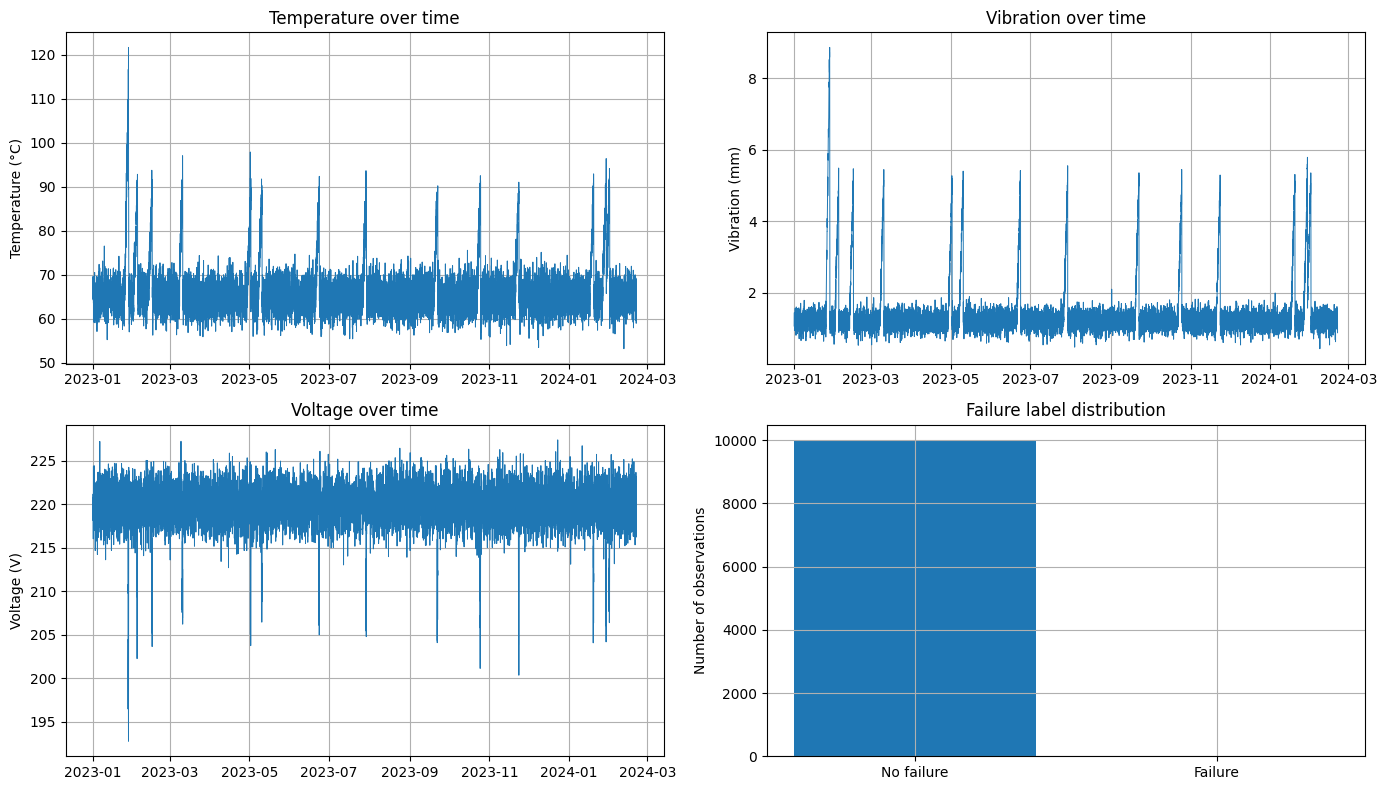

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.ravel()

axes[0].plot(df["Timestamp"], df["Sensor_Temp_C"], linewidth=0.7)
axes[0].set_title("Temperature over time")
axes[0].set_ylabel("Temperature (°C)")

axes[1].plot(df["Timestamp"], df["Sensor_Vibration_mm"], linewidth=0.7)
axes[1].set_title("Vibration over time")
axes[1].set_ylabel("Vibration (mm)")

axes[2].plot(df["Timestamp"], df["Sensor_Voltage_V"], linewidth=0.7)
axes[2].set_title("Voltage over time")
axes[2].set_ylabel("Voltage (V)")

failure_counts = df["Catastrophic_Failure"].value_counts().reindex([0, 1], fill_value=0)
axes[3].bar(["No failure", "Failure"], failure_counts.values)
axes[3].set_title("Failure label distribution")
axes[3].set_ylabel("Number of observations")

plt.tight_layout()
plt.show()

## 6. Phase 1 — Feature engineering (12-hour rolling windows)
A single unusual reading may be noise. Rolling statistics help capture sustained changes in machine condition.

- `Temp_Rolling_Mean_12h`: mean temperature over the current and previous 11 hours.
- `Vibration_Rolling_Std_12h`: standard deviation of vibration over the current and previous 11 hours.

The rolling calculations are performed after chronological sorting. Initial rows without a complete 12-hour window are removed.

In [5]:
df["Temp_Rolling_Mean_12h"] = (
    df["Sensor_Temp_C"].rolling(window=12, min_periods=12).mean()
)
df["Vibration_Rolling_Std_12h"] = (
    df["Sensor_Vibration_mm"].rolling(window=12, min_periods=12).std()
)

df = df.dropna(subset=[
    "Temp_Rolling_Mean_12h", "Vibration_Rolling_Std_12h"
]).copy()

print("Phase 1 complete.")
print("Shape after rolling-window NaN removal:", df.shape)
display(df[[
    "Timestamp", "Sensor_Temp_C", "Temp_Rolling_Mean_12h",
    "Sensor_Vibration_mm", "Vibration_Rolling_Std_12h"
]].head())

Phase 1 complete.
Shape after rolling-window NaN removal: (9989, 7)


,Timestamp,Sensor_Temp_C,Temp_Rolling_Mean_12h,Sensor_Vibration_mm,Vibration_Rolling_Std_12h
11,2023-01-01 11:00:00,63.602811,65.887866,1.370282,0.164662
12,2023-01-01 12:00:00,65.725887,65.824178,0.936841,0.178793
13,2023-01-01 13:00:00,59.260159,65.380424,1.106810,0.180102
14,2023-01-01 14:00:00,59.825247,64.787272,1.364598,0.181347
15,2023-01-01 15:00:00,63.313137,64.265943,1.208308,0.181415


## 7. Phase 2 — Target shifting (24-hour lead time)
`shift(-24)` moves the failure label from 24 rows in the future onto the current row. Therefore, the model learns:

**Given sensor readings at time _t_, will a catastrophic failure be recorded at time _t + 24 hours_?**

The supplied data is hourly, so 24 rows represent 24 hours. The last 24 rows have no known future label and must be removed. The original failure column is removed from the feature table to prevent target leakage.

In [6]:
df["Failure_In_24_Hours"] = df["Catastrophic_Failure"].shift(-24)
df = df.dropna(subset=["Failure_In_24_Hours"]).copy()
df["Failure_In_24_Hours"] = df["Failure_In_24_Hours"].astype(int)

# The timestamp is retained separately for time-based interpretation, not as a model feature.
feature_columns = [
    "Sensor_Temp_C",
    "Sensor_Vibration_mm",
    "Sensor_Voltage_V",
    "Temp_Rolling_Mean_12h",
    "Vibration_Rolling_Std_12h"
]

X = df[feature_columns].copy()
y = df["Failure_In_24_Hours"].copy()

assert "Catastrophic_Failure" not in X.columns
assert X.isna().sum().sum() == 0
assert y.isna().sum() == 0

print("Phase 2 complete.")
print("Rows available for modelling:", len(df))
print("24-hour-ahead target counts:")
display(y.value_counts().rename(index={0: "No failure in 24h", 1: "Failure in 24h"}))

Phase 2 complete.
Rows available for modelling: 9965
24-hour-ahead target counts:


Failure_In_24_Hours
No failure in 24h    9950
Failure in 24h         15
Name: count, dtype: int64

## 8. Phase 3 — Chronological train/test partition
Random shuffling is not appropriate for this time-series task because it can let future observations influence training. The first 80% of the timeline is reserved for model development; the final 20% is held out for the final test.

In [7]:
split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()
y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", df["Timestamp"].iloc[0], "to", df["Timestamp"].iloc[split_index - 1])
print("Testing period:", df["Timestamp"].iloc[split_index], "to", df["Timestamp"].iloc[-1])
print("Positive training labels:", int(y_train.sum()))
print("Positive test labels:", int(y_test.sum()))

assert df["Timestamp"].iloc[split_index - 1] < df["Timestamp"].iloc[split_index]

Training rows: 7972
Testing rows: 1993
Training period: 2023-01-01 11:00:00 to 2023-11-29 14:00:00
Testing period: 2023-11-29 15:00:00 to 2024-02-20 15:00:00
Positive training labels: 12
Positive test labels: 3


## 9. Phase 4 — Model training and threshold selection
A Random Forest is used because it can learn nonlinear relationships among sensor measurements and provides feature-importance scores. `class_weight="balanced"` gives greater weight to the rare failure class.

A default probability threshold of 0.50 can miss rare failures. To make the decision threshold data-driven without touching the final test set, the training period is split again chronologically into an inner training section and a validation section. The threshold with the best validation F1-score is selected, then the model is refitted on the complete 80% training period. The final 20% remains untouched until evaluation.

In [8]:
inner_split = int(len(X_train) * 0.80)
X_inner_train, X_validation = X_train.iloc[:inner_split], X_train.iloc[inner_split:]
y_inner_train, y_validation = y_train.iloc[:inner_split], y_train.iloc[inner_split:]

validation_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    min_samples_leaf=1,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
validation_model.fit(X_inner_train, y_inner_train)

validation_probabilities = validation_model.predict_proba(X_validation)[:, 1]

threshold_candidates = np.arange(0.05, 0.51, 0.01)
threshold_results = []
for threshold in threshold_candidates:
    validation_predictions = (validation_probabilities >= threshold).astype(int)
    threshold_results.append({
        "threshold": float(threshold),
        "precision": precision_score(y_validation, validation_predictions, zero_division=0),
        "recall": recall_score(y_validation, validation_predictions, zero_division=0),
        "f1": f1_score(y_validation, validation_predictions, zero_division=0)
    })

threshold_table = pd.DataFrame(threshold_results)
best_row = threshold_table.sort_values(
    ["f1", "recall", "precision"], ascending=[False, False, False]
).iloc[0]
decision_threshold = float(best_row["threshold"])

print("Selected validation threshold:", round(decision_threshold, 2))
print("Validation positive labels:", int(y_validation.sum()))
display(best_row.to_frame("Validation result"))

# Refit using all of the first 80% after selecting the threshold.
model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    min_samples_leaf=1,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
model.fit(X_train, y_train)

test_probabilities = model.predict_proba(X_test)[:, 1]
y_pred = (test_probabilities >= decision_threshold).astype(int)

print("Model training complete.")

Selected validation threshold: 0.16
Validation positive labels: 2


,Validation result
threshold,0.160000
precision,0.250000
recall,0.500000
f1,0.333333


Model training complete.


## 10. Final test evaluation
Because failures are rare, pay particular attention to **failure recall** (the fraction of actual failures detected) and precision (the fraction of alerts that were real failures). Also review the confusion matrix and average precision. A high accuracy score by itself can be misleading.

Confusion matrix (rows = actual, columns = predicted):
[[1987    3]
 [   1    2]]

Classification report:
                   precision    recall  f1-score   support

No failure in 24h       1.00      1.00      1.00      1990
   Failure in 24h       0.40      0.67      0.50         3

         accuracy                           1.00      1993
        macro avg       0.70      0.83      0.75      1993
     weighted avg       1.00      1.00      1.00      1993



,Metric,Value
0,Precision (failure),0.400000
1,Recall (failure),0.666667
2,F1-score (failure),0.500000
3,Balanced accuracy,0.832580
4,Average precision (PR AUC),0.289899


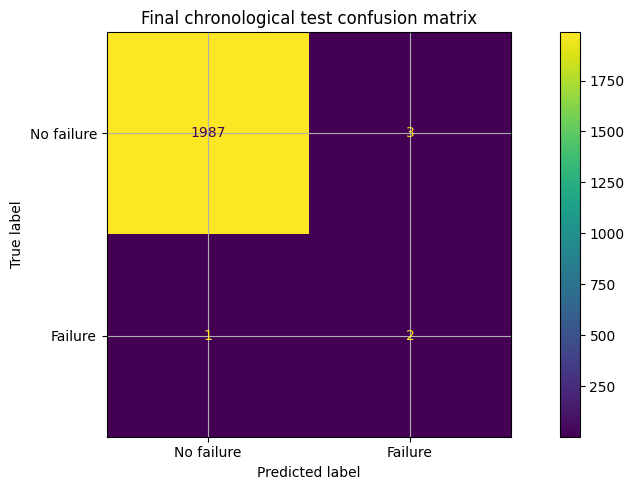

In [9]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)
print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["No failure in 24h", "Failure in 24h"],
    zero_division=0
))

test_precision = precision_score(y_test, y_pred, zero_division=0)
test_recall = recall_score(y_test, y_pred, zero_division=0)
test_f1 = f1_score(y_test, y_pred, zero_division=0)
test_balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
test_average_precision = average_precision_score(y_test, test_probabilities) if y_test.nunique() > 1 else np.nan

metrics = pd.DataFrame({
    "Metric": ["Precision (failure)", "Recall (failure)", "F1-score (failure)",
               "Balanced accuracy", "Average precision (PR AUC)"],
    "Value": [test_precision, test_recall, test_f1,
              test_balanced_accuracy, test_average_precision]
})
display(metrics)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No failure", "Failure"]
)
disp.plot(values_format="d")
plt.title("Final chronological test confusion matrix")
plt.tight_layout()
plt.show()

## 11. Phase 5 — Explainable AI: feature importance
The Random Forest feature-importance values show which inputs contributed most to the model's split decisions. They are useful for prioritising investigation, but they do not prove causation.

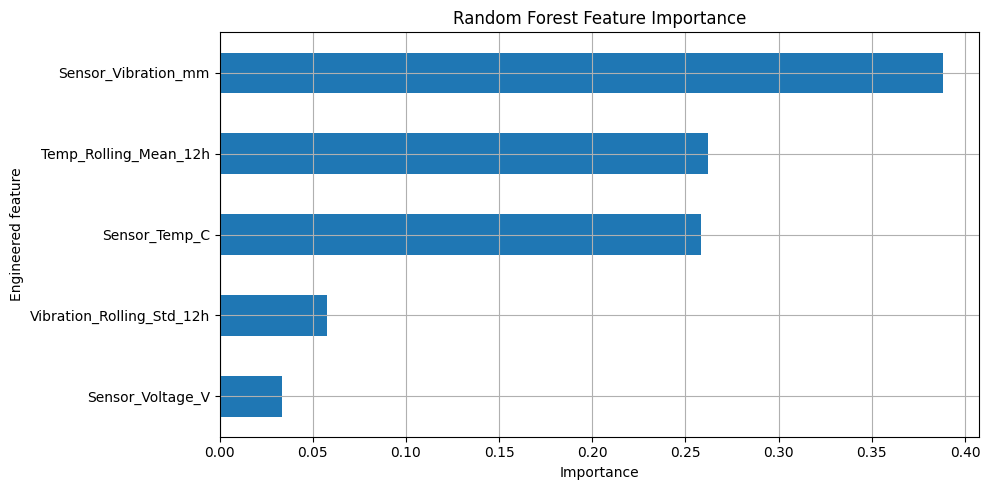

,Importance
Sensor_Vibration_mm,0.388341
Temp_Rolling_Mean_12h,0.261972
Sensor_Temp_C,0.258465
Vibration_Rolling_Std_12h,0.057672
Sensor_Voltage_V,0.033550


In [10]:
importances = pd.Series(model.feature_importances_, index=feature_columns)
importances = importances.sort_values(ascending=True)

plt.figure(figsize=(10, 5))
importances.plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Engineered feature")
plt.tight_layout()
plt.show()

display(importances.sort_values(ascending=False).rename("Importance").to_frame())

## 12. Maintenance recommendation
The next cell generates a recommendation from the model's measured feature-importance ranking and final test results. It avoids claiming that the model is production-ready solely from a small test set.

In [11]:
ranked_features = importances.sort_values(ascending=False)
top_feature = ranked_features.index[0]
second_feature = ranked_features.index[1]

print("BUSINESS RECOMMENDATION")
print("-----------------------")
print(f"1. Prioritise monitoring of {top_feature}, the highest-ranked model feature.")
print(f"2. Also monitor {second_feature} as the second-ranked feature.")
print(f"3. Use the selected alert threshold of {decision_threshold:.2f} as an investigation trigger,")
print("   not as an automatic machine shutdown command.")
print(f"4. The held-out test failure recall was {test_recall:.3f};")
print(f"   the model detected {int(((y_test == 1) & (y_pred == 1)).sum())} of {int(y_test.sum())} test-period failures.")
print("5. Before deployment, collect more failure examples, validate on later operating periods,")
print("   review false alarms with maintenance engineers, and monitor model drift.")

if int(y_test.sum()) < 20:
    print("\nLIMITATION: The test period contains fewer than 20 positive failure examples.")
    print("Performance estimates are therefore uncertain; additional labelled failure data is needed.")

BUSINESS RECOMMENDATION
-----------------------
1. Prioritise monitoring of Sensor_Vibration_mm, the highest-ranked model feature.
2. Also monitor Temp_Rolling_Mean_12h as the second-ranked feature.
3. Use the selected alert threshold of 0.16 as an investigation trigger,
   not as an automatic machine shutdown command.
4. The held-out test failure recall was 0.667;
   the model detected 2 of 3 test-period failures.
5. Before deployment, collect more failure examples, validate on later operating periods,
   review false alarms with maintenance engineers, and monitor model drift.

LIMITATION: The test period contains fewer than 20 positive failure examples.
Performance estimates are therefore uncertain; additional labelled failure data is needed.


## 13. Example: inspect the highest-risk test observations
This table lists test timestamps with the highest predicted probability of a failure 24 hours later. These are candidate inspection points, not confirmed faults.

In [12]:
risk_review = df.iloc[split_index:][["Timestamp"]].copy()
risk_review["Actual_Failure_In_24_Hours"] = y_test.to_numpy()
risk_review["Predicted_Failure_Probability"] = test_probabilities
risk_review["Predicted_Alert"] = y_pred
risk_review = risk_review.sort_values(
    "Predicted_Failure_Probability", ascending=False
).head(10)
display(risk_review.reset_index(drop=True))

,Timestamp,Actual_Failure_In_24_Hours,Predicted_Failure_Probability,Predicted_Alert
0,2024-01-31 06:00:00,0,0.380000,1
1,2024-01-28 15:00:00,0,0.353333,1
2,2024-01-28 14:00:00,1,0.300000,1
3,2024-01-19 00:00:00,0,0.246667,1
4,2024-01-31 05:00:00,1,0.190000,1
5,2024-01-18 22:00:00,0,0.156667,0
6,2024-01-28 10:00:00,0,0.143333,0
7,2024-01-31 08:00:00,0,0.123333,0
8,2024-01-28 17:00:00,0,0.100000,0
9,2024-01-18 19:00:00,0,0.093333,0


## 14. Conclusion
This project demonstrates an end-to-end predictive-maintenance workflow using the supplied IoT time-series data. It implements 12-hour rolling features, a 24-hour-ahead shifted target, a chronological 80/20 split, a class-weighted Random Forest, rare-event evaluation and feature-importance analysis.

**Deployment note:** This is an academic prototype. The dataset contains very few recorded failure events, so test metrics can vary substantially. A real deployment would require more labelled failure examples, validation on additional future periods, engineering review of alerts, and continuous monitoring.

### Deliverable checklist
- [x] Timestamp parsing and chronological sorting
- [x] 12-hour rolling temperature mean
- [x] 12-hour rolling vibration standard deviation
- [x] 24-hour target shift using `shift(-24)`
- [x] Removal of original failure target from features
- [x] Chronological 80/20 split
- [x] Random Forest with balanced class weights
- [x] Classification metrics and confusion matrix
- [x] Matplotlib horizontal feature-importance chart
- [x] Business recommendation